<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Pie Charts**


Estimated time needed: **30** minutes


- In this lab, you will focus on visualizing data.

- The provided dataset will be loaded into pandas for analysis.

- Various pie charts will be created to:
   - Analyze developer preferences.
  
   - Identify technology usage trends.
    
- The lab aims to provide insights into key variables using visual representations.


## Objectives


In this lab you will perform the following:


-   Visualize the distribution of data.

-   Visualize the relationship between two features.

-   Visualize composition of data.

-   Visualize comparison of data.


## Setup: Downloading and Loading the Data
**Install the libraries**


In [ ]:
# !pip install pandas

In [ ]:
# !pip install matplotlib

**Download and Load the Data**


To start, download and load the dataset into a `pandas` DataFrame.



In [1]:
# Step 1: Download the dataset
# !wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

# Step 2: Import necessary libraries and load the dataset
import pandas as pd
import matplotlib.pyplot as plt

# Load the data
df = pd.read_csv("survey_data.csv")

# Display the first few rows to understand the structure of the data
df.head()


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Visualizing Data Composition with Pie Charts


##### 1.1 Create a Pie Chart of the Top 5 Databases Respondents Want to Work With


In the survey data, the `DatabaseWantToWorkWith` column lists the databases that respondents wish to work with. Let’s visualize the top 5 most-desired databases in a pie chart.



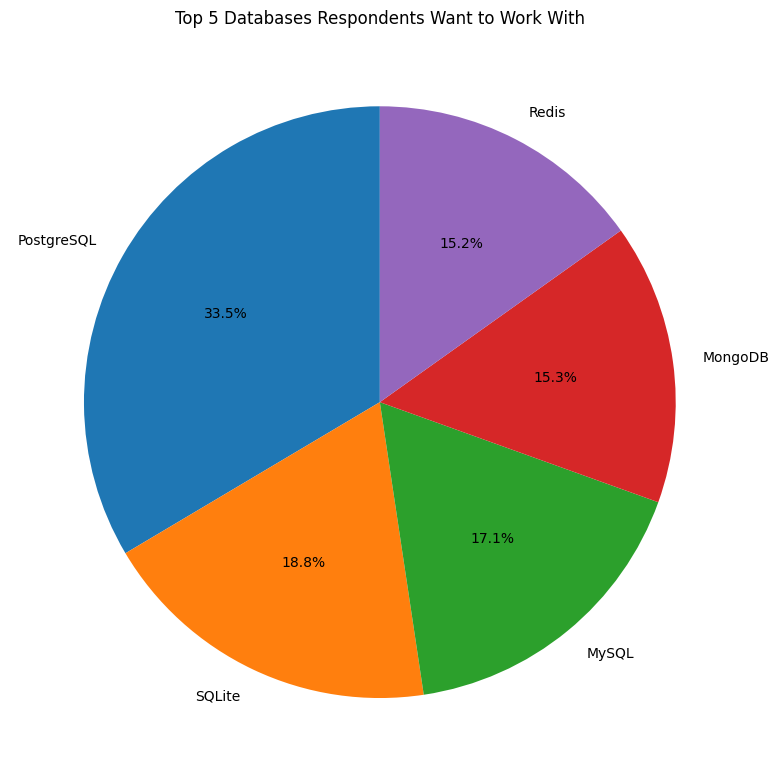

In [2]:
# drop rows with missing values
db_df = df[['DatabaseWantToWorkWith']].dropna()

# Split into separate rows and remove whitespaces
db_df['Databases'] = db_df['DatabaseWantToWorkWith'].str.split(';')
db_df = db_df.explode('Databases')
db_df['Databases'] = db_df['Databases'].str.strip()

# Get to 5 databases with the highest counts
top5_databases = db_df['Databases'].value_counts().nlargest(5)

# Create a pie chart
plt.figure(figsize=(8,8))
plt.pie(
    top5_databases,
    labels=top5_databases.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Top 5 Databases Respondents Want to Work With')
plt.tight_layout()
plt.show()

The `DevType` column lists the developer types for respondents. We’ll examine the distribution by showing the top 5 developer roles in a pie chart.



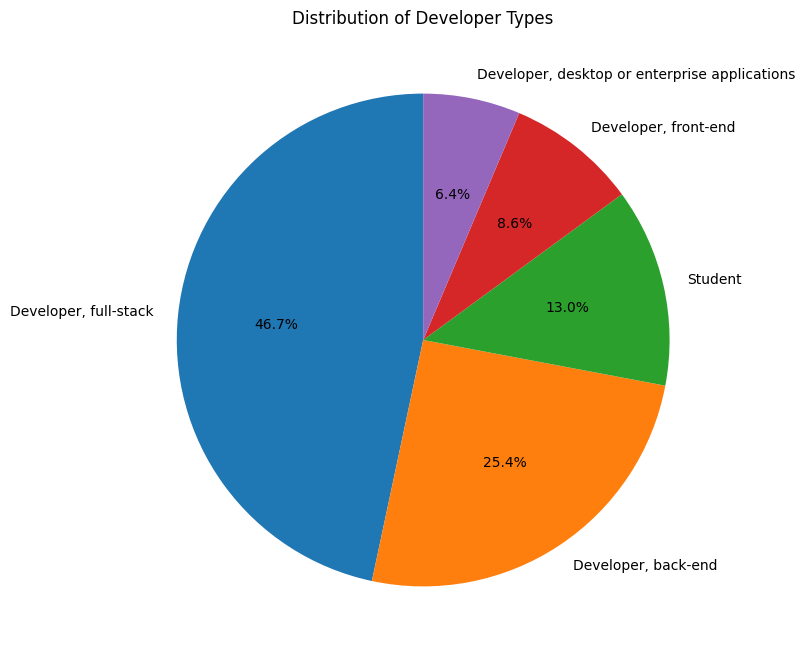

In [6]:
devtype_df = df[['DevType']].dropna()

devtype_df['DevType'] = devtype_df['DevType'].str.split(';')
devtype_df = devtype_df.explode('DevType')
devtype_df['DevType'] = devtype_df['DevType'].str.strip()

top5_developer_types = devtype_df['DevType'].value_counts().nlargest(5)

plt.figure(figsize=(8,8))
plt.pie(
    top5_developer_types,
    labels=top5_developer_types.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Developer Types')
plt.show()

##### 1.3 Create a pie chart for the operating systems used by respondents for professional use


The `OpSysProfessional` use column shows the operating systems developers use professionally. Let’s visualize the distribution of the top operating systems in a pie chart.



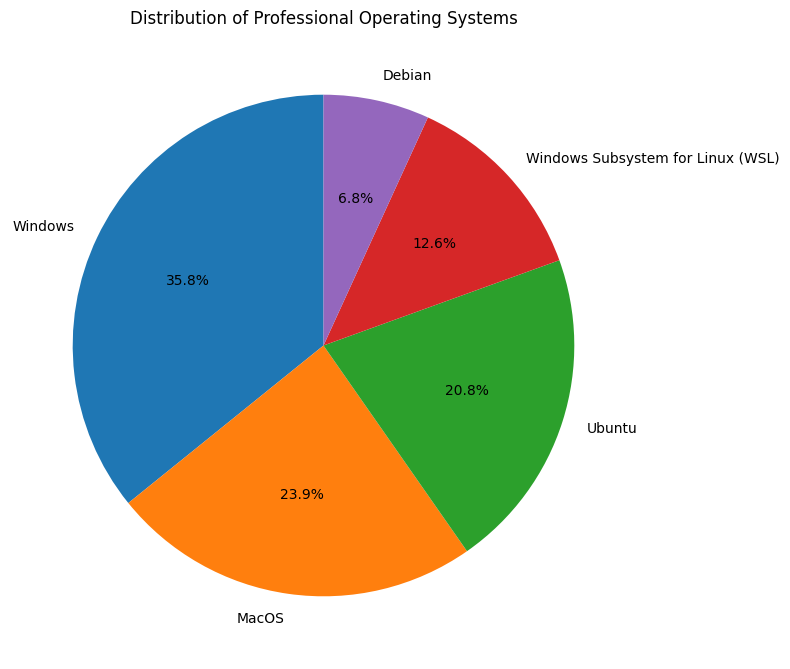

In [19]:
os_df = df[['OpSysProfessional use']].dropna()
# Split operating systems into separate rows
os_df['OperatingSystem'] = os_df['OpSysProfessional use'].str.split(';')
os_df = os_df.explode('OperatingSystem')

# Remove extra spaces
os_df['OperatingSystem'] = os_df['OperatingSystem'].str.strip()

os_counts = os_df['OperatingSystem'].value_counts().nlargest(5)

plt.figure(figsize=(8,8))
plt.pie(
    os_counts,
    labels=os_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Professional Operating Systems')
plt.tight_layout()
plt.show()

### Task 2: Additional Visualizations and Comparisons


##### 2.1 Pie Chart for Top 5 Programming Languages Respondents Have Worked With


The `LanguageHaveWorkedWith` column contains the programming languages that respondents have experience with. We’ll plot a pie chart to display the composition of the top 5 languages.



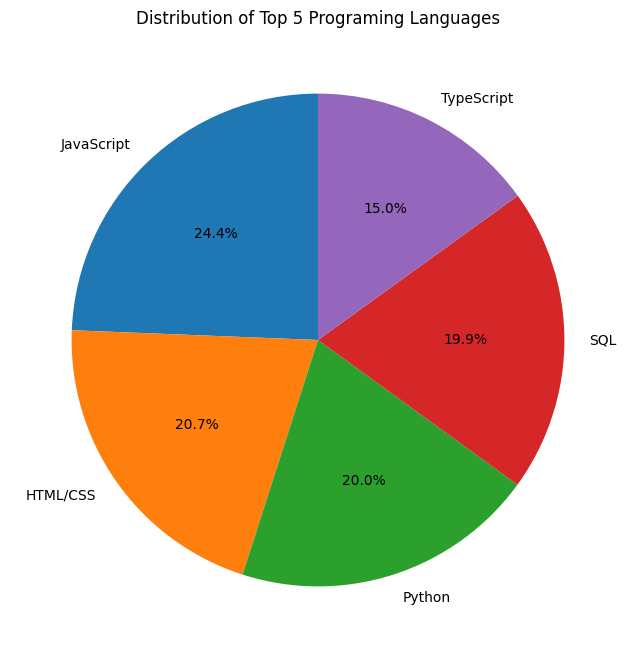

In [20]:
df_language = df[['LanguageHaveWorkedWith']].dropna()

df_language['Language'] = df_language['LanguageHaveWorkedWith'].str.split(';')
df_language = df_language.explode('Language')
df_language['Language'] = df_language['Language'].str.strip()

lang_count = df_language['Language'].value_counts().nlargest(5)

plt.figure(figsize=(8,8))
plt.pie(
    lang_count,
    labels=lang_count.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Distribution of Top 5 Programing Languages")
plt.show()

##### 2.2 Pie Chart for Top Collaboration Tools used in Professional Use


Using the `NEWCollabToolsHaveWorkedWith` column, we’ll identify and visualize the top collaboration tools respondents use in their professional work.



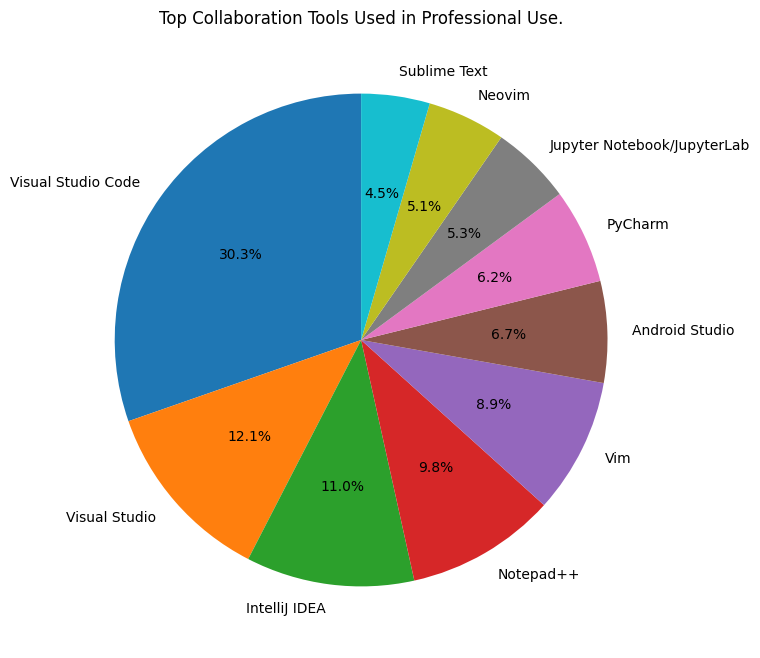

In [ ]:
# Keep non-null values
df_collab = df[['NEWCollabToolsHaveWorkedWith']].dropna()

# Split multiple tools into separate rows and remove extra spaces
df_collab['Collab_Tools'] = df['NEWCollabToolsHaveWorkedWith'].str.split(';')
df_collab = df_collab.explode('Collab_Tools')
df_collab['Collab_Tools'] = df_collab['Collab_Tools'].str.strip()

# Count tools frequencies
collab_count = df_collab['Collab_Tools'].value_counts().nlargest(10)

plt.figure(figsize=(8,8))
plt.pie(
    collab_count,
    labels=collab_count.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Top Collaboration Tools Used in Professional Use.")
plt.show()

### Task 3: Analyzing and Interpreting Composition


In this task, you will create additional pie charts to analyze specific aspects of the survey data. Use `pandas` and `matplotlib` to complete each task and interpret the findings.



##### 3.1 Pie Chart of `Respondents` Most Admired Programming Languages


The `LanguageAdmired` column lists the programming languages respondents admire most. Create a pie chart to visualize the top 5 admired languages.



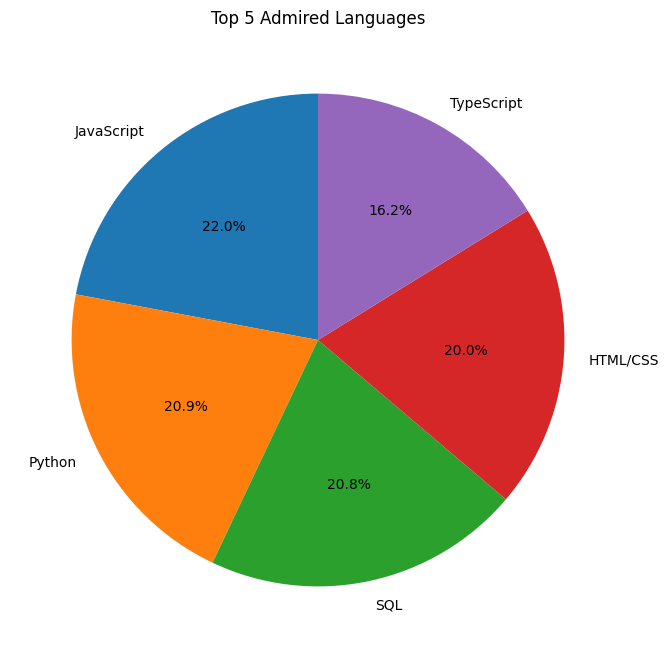

In [6]:
# Keep non-null values
df_lang = df[['LanguageAdmired']].dropna()

# Split multiple languages into separate rows and remove extra spaces
df_lang['Language'] = df_lang['LanguageAdmired'].str.split(';')
df_lang = df_lang.explode('Language')
df_lang['Language'] = df_lang['Language'].str.strip()

# Get top 5 admired languages
top5_languages = df_lang['Language'].value_counts().nlargest(5)

# plot pie chart
plt.figure(figsize=(8,8))
plt.pie(
    top5_languages,
    labels=top5_languages.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Top 5 Admired Languages")
plt.show()

##### 3.2 Pie Chart of Tools Used for AI Development


Using the `AIToolCurrently` Using column, create a pie chart to visualize the top 5 tools developers are currently using for AI development.



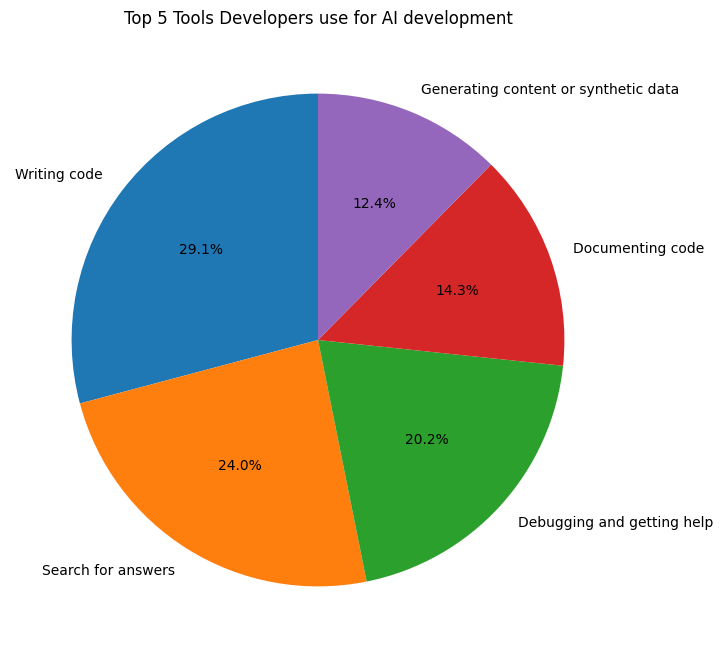

In [13]:
# Drop null values
df_AI = df[['AIToolCurrently Using']].dropna()

# Split multiple AI tools into separate rows and remove extra spaces
df_AI['AI_Tool'] = df_AI['AIToolCurrently Using'].str.split(';')
df_AI = df_AI.explode('AI_Tool')
df_AI['AI_Tool'] = df_AI['AI_Tool'].str.strip()

# Get top 5 AI tools
top5_AI_tools = df_AI['AI_Tool'].value_counts().nlargest(5)

# plot pie chart
# plot pie chart
plt.figure(figsize=(8,8))
plt.pie(
    top5_AI_tools,
    labels=top5_AI_tools.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Top 5 Tools Developers use for AI development")
plt.show()

##### 3.3 Pie Chart for Preferred Web Frameworks


The `WebframeWantToWorkWith` column includes web frameworks that respondents are interested in working with. Visualize the top 5 frameworks in a pie chart.



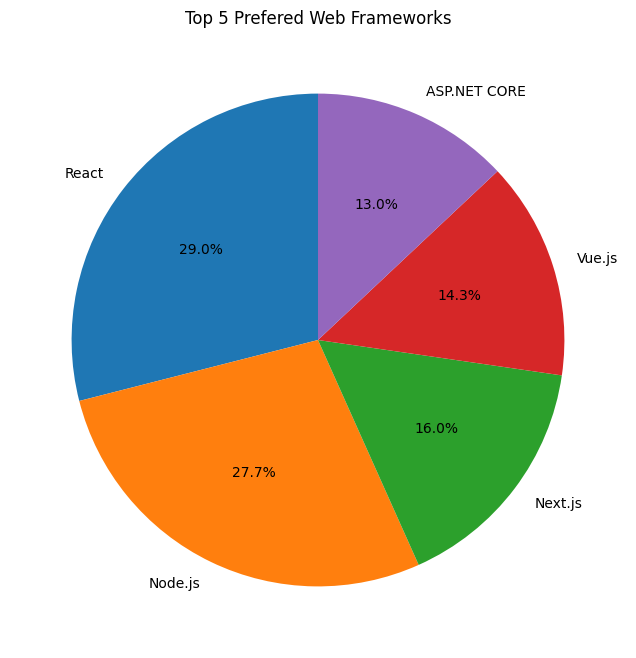

In [17]:
# Drop null values
df_web = df[['WebframeWantToWorkWith']].dropna()

# Split multiple web Frameworks into separate rows and remove extra spaces
df_web['web_frame'] = df_web['WebframeWantToWorkWith'].str.split(';')
df_web = df_web.explode('web_frame')
df_web['web_frame'] = df_web['web_frame'].str.strip()

# Get top 5 web_frameworks
top5_web_frameworks = df_web['web_frame'].value_counts().nlargest(5)

# plot pie chart
plt.figure(figsize=(8,8))
plt.pie(
    top5_web_frameworks,
    labels=top5_web_frameworks.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Top 5 Prefered Web Frameworks")
plt.show()

##### 3.4 Pie Chart for Most Desired Embedded Technologies


Using the `EmbeddedWantToWorkWith` column, create a pie chart to show the top 5 most desired embedded technologies that respondents wish to work with.



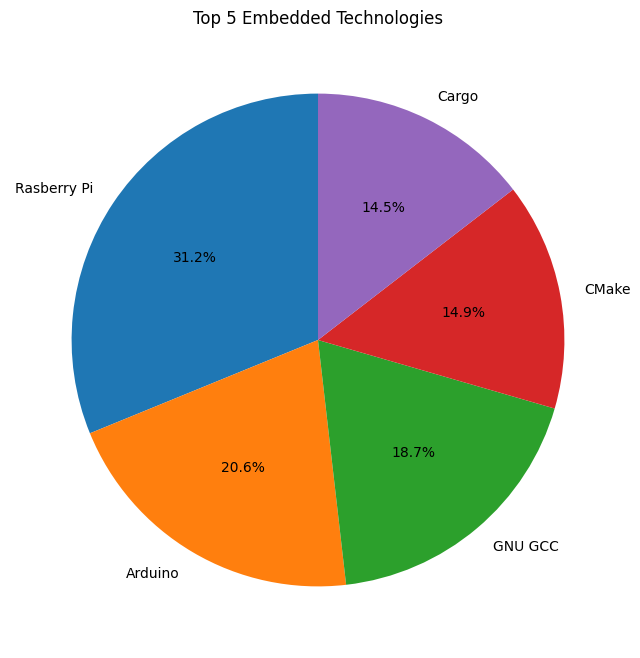

In [18]:
# Drop null values
df_emb_tech = df[['EmbeddedWantToWorkWith']].dropna()

# Split multiple Technologies into separate rows and remove extra spaces
df_emb_tech['embedded_tech'] = df_emb_tech['EmbeddedWantToWorkWith'].str.split(';')
df_emb_tech = df_emb_tech.explode('embedded_tech')
df_emb_tech['embedded_tech'] = df_emb_tech['embedded_tech'].str.strip()

# Get top 5 technologies
top5_embedde_tech = df_emb_tech['embedded_tech'].value_counts().nlargest(5)

# plot pie chart
plt.figure(figsize=(8,8))
plt.pie(
    top5_embedde_tech,
    labels=top5_embedde_tech.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Top 5 Embedded Technologies")
plt.show()

### Summary


After completing this lab, you will be able to:
- Create pie charts to visualize developer preferences across databases, programming languages, AI tools, and cloud platforms.
- Identify trends in technology usage, role distribution, and tool adoption through pie charts.
- Analyze and compare data composition across various categories to gain insights into developer preferences.




## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
